# Mathematical Foundations of Support Vector Machines (SVM)

This notebook builds the mathematical ideas behind a **linear Support Vector Machine (SVM)**, from a separating hyperplane to the maximum-margin optimization problem, hinge loss, and the kernel trick.

## Learning goals

By the end, you should be able to explain:

1. How a linear classifier makes predictions.
2. What the decision boundary \(w^\top x+b=0\) represents.
3. Why SVM maximizes the margin.
4. How the hard-margin and soft-margin optimization problems differ.
5. What hinge loss and the parameter \(C\) do.
6. How kernels allow nonlinear decision boundaries.

We will use equations, small numerical examples, and visualizations. The examples are educational; real datasets may need scaling, validation, and hyperparameter tuning.

```markdown
## 1. The classification problem

Imagine we have two groups of items we want to separate—for example, healthy cells (Class +1) and tumor cells (Class -1).

Each item has a set of measured features (like cell size and cell roundness). Our goal is to find a rule (a line or boundary) that splits these two groups apart as cleanly as possible, so that when we get a new cell, we can instantly predict which group it belongs to.
```

```markdown
## 2. A linear decision function (The Dividing Line)

A linear SVM tries to draw a straight line (in 2D) or a flat plane (in 3D) between the two classes. Mathematically, we represent this dividing boundary as a hyperplane:

$$w^\top x + b = 0$$

To make a decision for any new data point $x$, we calculate its **score**:

$$\text{Score} = w^\top x + b = (w_1 \times x_1) + (w_2 \times x_2) + b$$

- If $\text{Score} \geq 0$, we predict **Class +1**.
- If $\text{Score} < 0$, we predict **Class -1**.

The boundary where the score is exactly **0** is our **decision boundary** (the fence).

### Simple Example
Let's say our parameters are $w = [2, 1]$ and $b = -3$. The boundary formula is: $\text{Score} = 2x_1 + x_2 - 3 = 0$
- For a point at $(2, 1)$, the score is $2(2) + 1(1) - 3 = 2$ (Positive $
ightarrow$ Class +1).
- For a point at $(0, 1)$, the score is $2(0) + 1(1) - 3 = -2$ (Negative $
ightarrow$ Class -1).
```

In [18]:
import numpy as np
import matplotlib.pyplot as plt

w = np.array([2.0, 1.0])
b = -3.0
examples = np.array([[2, 1], [0, 1], [1, 1.5]])

scores = examples @ w + b
predictions = np.where(scores >= 0, 1, -1)

for x, score, pred in zip(examples, scores, predictions):
    print(f"x={x}, score={score:.1f}, predicted class={pred:+d}")

x=[2. 1.], score=2.0, predicted class=+1
x=[0. 1.], score=-2.0, predicted class=-1
x=[1.  1.5], score=0.5, predicted class=+1


```markdown
## 3. The "Safety Margin" Concept

Unlike other classifiers that just find *any* line that separates classes, SVM wants to find the **safest** line.

Think of the decision boundary as the middle of a street. SVM tries to make the street as **wide** as possible. The distance from the middle line to the closest points on either side is the **margin**.

Mathematically, the width of this street (the margin) is defined as:

$$\text{Margin Width} = \frac{2}{\|w\|_2}$$

where $\|w\|_2 = \sqrt{w_1^2 + w_2^2}$ is the length (norm) of the weight vector.
- To make the margin as **large** as possible, the SVM algorithm must minimize the weights $\|w\|_2$.
```

```markdown
### 📐 Geometric Explanation of the Margin

Why does the margin relate to $\frac{1}{\|w\|_2}$?

1. **The Boundaries**: We define three parallel lines (hyperplanes):
   - **Decision Boundary**: $w^\top x + b = 0$
   - **Positive Margin Boundary**: $w^\top x + b = 1$
   - **Negative Margin Boundary**: $w^\top x + b = -1$

2. **The Weight Vector ($w$)**: The vector $w$ is always **perpendicular** (orthogonal) to the decision boundary, pointing in the direction of the positive class.

3. **Calculating the Distance**:
   - Let $x_0$ be a point on the decision boundary ($w^\top x_0 + b = 0$).
   - To reach the positive margin, we travel in the direction of the unit normal vector $\frac{w}{\|w\|_2}$ by some distance $d$.
   - The new point is $x_+ = x_0 + d \frac{w}{\|w\|_2}$.
   - Since $x_+$ lies on the positive margin, it must satisfy its equation:
     $$w^\top \left( x_0 + d \frac{w}{\|w\|_2} \right) + b = 1$$
   - Expanding this:
     $$\underbrace{w^\top x_0 + b}_{0} + d \frac{w^\top w}{\|w\|_2} = 1 \implies d \frac{\|w\|_2^2}{\|w\|_2} = 1 \implies d \|w\|_2 = 1 \implies d = \frac{1}{\|w\|_2}$$

Thus, the distance from the center line to either margin is exactly **$\frac{1}{\|w\|_2}$**, making the total street width (the margin) **$\frac{2}{\|w\|_2}$**!
```

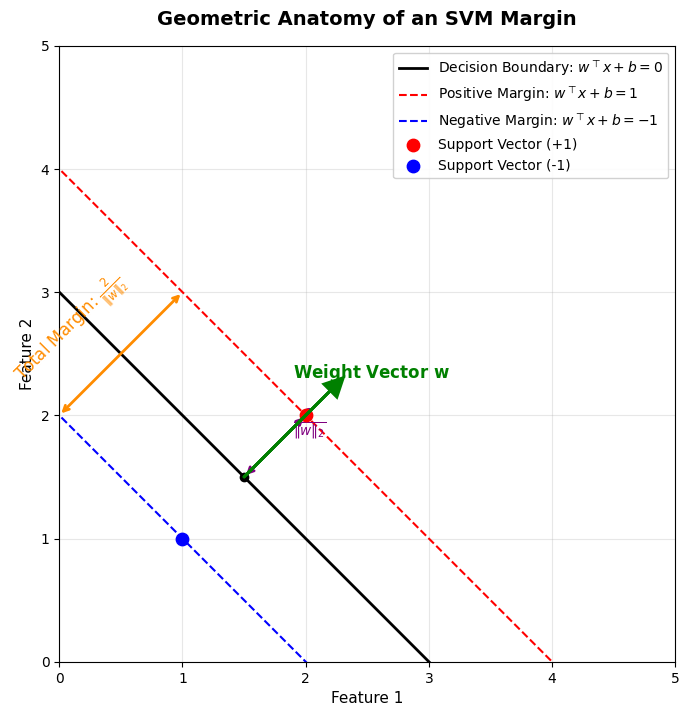

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Set up the figure
plt.figure(figsize=(8, 8))

# Define space range
x = np.linspace(-2, 6, 200)

# Boundaries:
# w^T x + b = 0  => x2 = -x1 + 3
# w^T x + b = 1  => x2 = -x1 + 4
# w^T x + b = -1 => x2 = -x1 + 2

plt.plot(x, -x + 3, 'k-', linewidth=2, label=r'Decision Boundary: $w^\top x + b = 0$')
plt.plot(x, -x + 4, 'r--', linewidth=1.5, label=r'Positive Margin: $w^\top x + b = 1$')
plt.plot(x, -x + 2, 'b--', linewidth=1.5, label=r'Negative Margin: $w^\top x + b = -1$')

# Highlight key points
x_0 = np.array([1.5, 1.5]) # On the boundary
w = np.array([1.0, 1.0])
w_norm = np.linalg.norm(w) # sqrt(2)

# Point on positive margin
x_plus = x_0 + (1/w_norm) * (w/w_norm)
# Point on negative margin
x_minus = x_0 - (1/w_norm) * (w/w_norm)

# Draw points
plt.scatter([x_0[0]], [x_0[1]], color='black', zorder=5)
plt.scatter([x_plus[0]], [x_plus[1]], color='red', s=80, zorder=5, label='Support Vector (+1)')
plt.scatter([x_minus[0]], [x_minus[1]], color='blue', s=80, zorder=5, label='Support Vector (-1)')

# Plot the weight vector w starting from the decision boundary
plt.arrow(x_0[0], x_0[1], 0.7, 0.7, head_width=0.15, head_length=0.15, fc='g', ec='g', linewidth=2, zorder=6)
plt.text(x_0[0]+0.4, x_0[1]+0.8, r'Weight Vector $\mathbf{w}$', color='green', fontsize=12, fontweight='bold')

# Draw double-sided dimension arrows for distances
# Distance from boundary to positive margin
plt.annotate('', xy=x_plus, xytext=x_0,
             arrowprops=dict(arrowstyle='<->', color='purple', lw=2))
plt.text(1.9, 1.9, r'$\frac{1}{\|w\|_2}$', color='purple', fontsize=14, fontweight='bold')

# Distance between margins (total margin width)
# Let's shift it to the side for clarity
shift = np.array([-1.0, 1.0])
plt.annotate('', xy=x_plus + shift, xytext=x_minus + shift,
             arrowprops=dict(arrowstyle='<->', color='darkorange', lw=2))
plt.text(x_0[0] + shift[0] - 0.9, x_0[1] + shift[1] - 0.2, r'Total Margin: $\frac{2}{\|w\|_2}$',
         color='darkorange', fontsize=12, rotation=45)

# Decorate the plot
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlabel('Feature 1', fontsize=11)
plt.ylabel('Feature 2', fontsize=11)
plt.title('Geometric Anatomy of an SVM Margin', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='upper right', framealpha=0.9)
plt.grid(True, alpha=0.3)
plt.show()

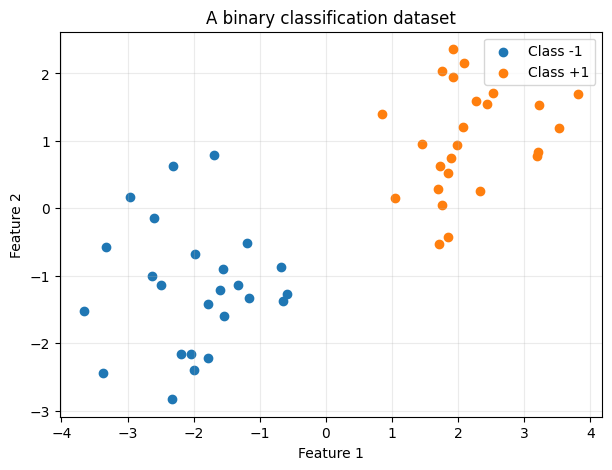

In [19]:
# Visualize a simple, linearly separable 2D dataset
from sklearn.datasets import make_blobs

X, y01 = make_blobs(
    n_samples=50, centers=[(-2, -1), (2, 1)],
    cluster_std=0.8, random_state=7
)
y = np.where(y01 == 0, -1, 1)

plt.figure(figsize=(7, 5))
plt.scatter(X[y == -1, 0], X[y == -1, 1], label="Class -1")
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Class +1")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("A binary classification dataset")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

```markdown
## 4. What are Support Vectors?

If you build a street, only the houses right on the edge of the curb limit how wide the street can be. The houses further back in the neighborhood don't affect the road width at all.

In SVM, the data points that lie directly on the edge of the margin are called **Support Vectors**.
- If you move or remove these points, the boundary line will change.
- If you move any other points that are safely behind the margins, the boundary line stays exactly the same!
```

In [20]:
from sklearn.svm import SVC

linear_svm = SVC(kernel="linear", C=1.0)
linear_svm.fit(X, y)

print("Number of support vectors:", len(linear_svm.support_))
print("Support vectors by class:", linear_svm.n_support_)

Number of support vectors: 2
Support vectors by class: [1 1]


```markdown
## 5. Hard-Margin SVM: Perfect Separation

In a **Hard-Margin SVM**, we assume the data is perfectly clean and separable. We enforce a strict rule:
- **No mistakes allowed!** Every single point $x_i$ must lie on the correct side of the boundary, outside of the street margin.

We express this mathematically as a constraint for every point $i$:

$$y_i(w^\top x_i + b) \geq 1$$

where $y_i \in \{-1, +1\}$ is the true class label.

Our objective is to find $w$ and $b$ to:

$$\text{Minimize } \frac{1}{2}\|w\|^2 \quad \text{subject to } y_i(w^\top x_i + b) \geq 1 \text{ for all } i$$

*Why this can fail:* If just one outlier point from Class -1 accidentally crosses over to Class +1's side, a hard-margin SVM will either completely fail to find any solution, or make a very narrow, highly skewed margin that performs poorly on new data.
```

```markdown
## 6. Soft-Margin SVM: Allowing Some Mistakes

Real-world data is messy, and classes often overlap. To handle this, **Soft-Margin SVM** introduces helper variables $\xi_i$ (slack variables) that represent how much a point violates the margin. We also introduce a penalty control parameter **$C$**:

$$\text{Minimize } \frac{1}{2}\|w\|^2 + C \sum_{i=1}^{n} \xi_i \quad \text{subject to } y_i(w^\top x_i + b) \geq 1 - \xi_i \quad (\xi_i \geq 0)$$

- **Large $C$ (Strict)**: The model behaves like a strict teacher. It penalizes errors heavily, trying to classify every training point correctly, even if it makes the "safety street" (margin) very narrow.
- **Small $C$ (Relaxed)**: The model is more relaxed. It is willing to accept some misplaced points inside the street or even on the wrong side, in exchange for keeping the overall safety margin wide and simple.
```

```markdown
## 7. Hinge Loss: How SVM Measures Errors

To find the best balance, SVM uses a penalty loss function called **Hinge Loss**:

$$\mathcal{L}_{hinge}(x_i, y_i) = \max(0, 1 - y_i(w^\top x_i + b))$$

- If a point is on the correct side and safely outside the street ($y_i(w^\top x_i + b) \geq 1$), its loss is **0**.
- If a point steps inside the street or crosses to the wrong side, its loss increases linearly with how far off it is.
```

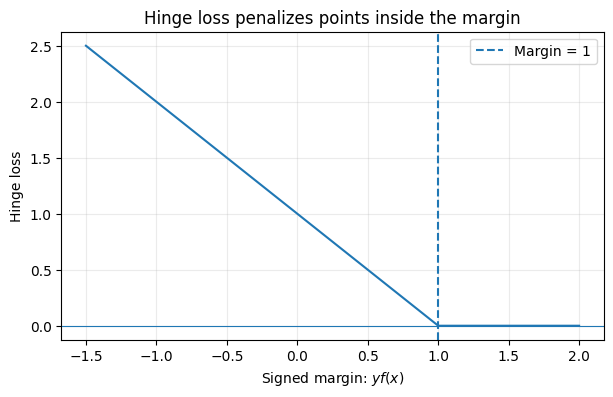

In [21]:
import numpy as np
import matplotlib.pyplot as plt

margins = np.linspace(-1.5, 2.0, 300)  # y * f(x)
hinge = np.maximum(0, 1 - margins)

plt.figure(figsize=(7, 4))
plt.plot(margins, hinge)
plt.axvline(1, linestyle="--", label="Margin = 1")
plt.axhline(0, linewidth=0.8)
plt.xlabel(r"Signed margin: $y f(x)$")
plt.ylabel("Hinge loss")
plt.title("Hinge loss penalizes points inside the margin")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

```markdown
## 8. Why We Focus on Similarities

When we mathematically solve the SVM optimization, we discover an elegant shortcut: the algorithm doesn't need to know the absolute positions of points; it only needs to know how **similar** (or close) the points are to each other.

This "similarity-only" perspective is what allows us to scale up to non-linear datasets using a trick called Kernels.
```

```markdown
## 9. The Kernel Trick: Handling Curvy Boundaries

What if a straight line cannot separate our classes (like a circle of blue dots surrounded by red dots)?

Instead of bending our straight boundary, we project our points into a **higher-dimensional space** where they *can* be split by a flat sheet of paper.

Instead of doing complex 3D or 4D calculations, a **Kernel function** lets us calculate similarities directly in this high-dimensional space without ever actually building it. The most popular one is the **RBF (Gaussian) Kernel**, which acts like a spotlight around support vectors, grouping points by physical proximity.
```

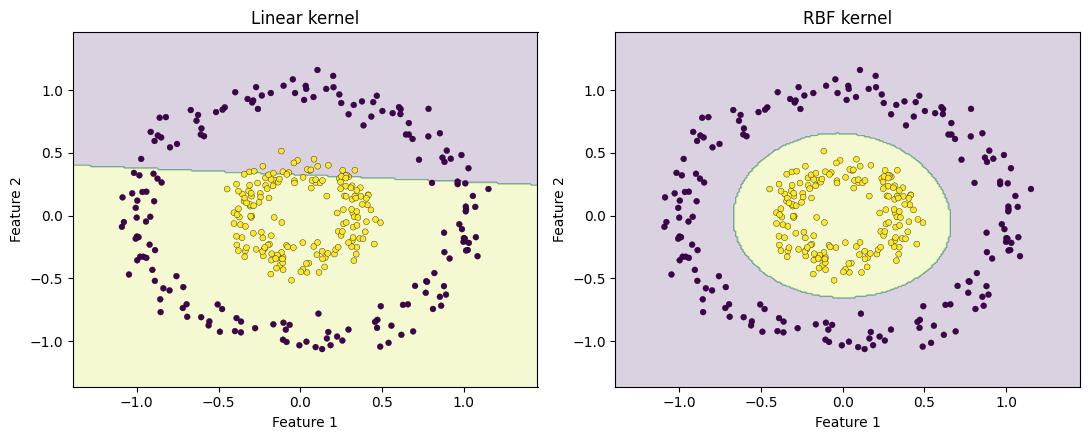

In [22]:
from sklearn.datasets import make_circles
from sklearn.svm import SVC

X_c, y_c = make_circles(n_samples=350, factor=0.35, noise=0.08, random_state=4)

models = [
    ("Linear kernel", SVC(kernel="linear", C=1.0)),
    ("RBF kernel", SVC(kernel="rbf", C=1.0, gamma="scale")),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, models):
    model.fit(X_c, y_c)
    xx, yy = np.meshgrid(
        np.linspace(X_c[:, 0].min() - 0.3, X_c[:, 0].max() + 0.3, 250),
        np.linspace(X_c[:, 1].min() - 0.3, X_c[:, 1].max() + 0.3, 250),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.2)
    ax.scatter(X_c[:, 0], X_c[:, 1], c=y_c, s=18, edgecolors="k", linewidths=0.25)
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

## 10. A practical experiment: train and evaluate an SVM

This example uses the Breast Cancer Wisconsin dataset bundled with scikit-learn. It is a **binary classification** task. We scale features inside a pipeline because SVMs are sensitive to feature scale, then evaluate on a held-out test set.

For a real project, use cross-validation to tune `C` and kernel parameters rather than selecting them based on test-set performance.

In [23]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.25, random_state=42, stratify=data.target
)

model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, pred):.3f}")
print("\nConfusion matrix:")
print(confusion_matrix(y_test, pred))
print("\nClassification report:")
print(classification_report(y_test, pred, target_names=data.target_names))

Test accuracy: 0.979

Confusion matrix:
[[52  1]
 [ 2 88]]

Classification report:
              precision    recall  f1-score   support

   malignant       0.96      0.98      0.97        53
      benign       0.99      0.98      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143



## 11. What to remember

- The decision function is \(f(x)=w^\top x+b\).
- The boundary is \(w^\top x+b=0\).
- The geometric margin width is \(2/\|w\|_2\) under canonical scaling.
- SVM maximizes the margin by minimizing \(\frac12\|w\|_2^2\).
- Soft-margin SVM uses slack variables or hinge loss to handle imperfectly separable data.
- \(C\) controls the trade-off between margin size and violations.
- Support vectors are the training examples that determine the boundary.
- Kernels let SVM model nonlinear relationships through dot products in an implicit feature space.
- Feature scaling is usually important, and model selection should use validation data.

## 12. Check your understanding

Try answering these before checking your notes:

1. Why does minimizing \(\|w\|_2\) maximize the margin?
2. What does the constraint \(y_i(w^\top x_i+b)\geq1\) mean geometrically?
3. What is the effect of increasing \(C\)?
4. Why do only some training points become support vectors?
5. How does a kernel help when the classes are not linearly separable?
6. Why should feature scaling be fitted on the training set only?

### Short answers

1. The margin width is \(2/\|w\|_2\), so a smaller norm gives a wider margin.
2. Each point is correctly classified and lies on or beyond its class's margin boundary.
3. Violations become more expensive, so the fit prioritizes training violations more strongly.
4. Those points have nonzero dual coefficients and help define the separating boundary.
5. It evaluates similarities corresponding to dot products in a richer feature space without explicitly constructing that space.
6. To avoid leaking information from the test set into training; a pipeline handles this correctly.

# Additional Task: Explore the effect of C and Gamma



In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.svm import SVC
from ipywidgets import interact, FloatLogSlider, Dropdown

# Generate a slightly noisy, non-linear dataset
X_m, y_m = make_moons(n_samples=150, noise=0.2, random_state=42)

def plot_interactive_svm(C, gamma):
    clf = SVC(kernel='rbf', C=C, gamma=gamma)
    clf.fit(X_m, y_m)

    # Setup meshgrid for decision boundaries
    x_min, x_max = X_m[:, 0].min() - 0.5, X_m[:, 0].max() + 0.5
    y_min, y_max = X_m[:, 1].min() - 0.5, X_m[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

    # Predict decision score
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 5))
    # Plot boundary and margins
    plt.contourf(xx, yy, Z, levels=50, cmap=plt.cm.coolwarm, alpha=0.3)
    contour = plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=['blue', 'black', 'red'],
                          linestyles=['--', '-', '--'], linewidths=[1.5, 2, 1.5])
    plt.clabel(contour, inline=True, fontsize=10, fmt={-1: '-1 (Margin)', 0: '0 (Boundary)', 1: '+1 (Margin)'})

    # Plot training points and highlight support vectors
    plt.scatter(X_m[y_m == 0, 0], X_m[y_m == 0, 1], color='blue', label='Class -1', edgecolors='k')
    plt.scatter(X_m[y_m == 1, 0], X_m[y_m == 1, 1], color='red', label='Class +1', edgecolors='k')
    plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=120,
                facecolors='none', edgecolors='green', linewidths=2, label='Support Vectors')

    plt.title(f"RBF SVM Decision Boundary (C={C:.2e}, gamma={gamma:.2e})")
    plt.legend(loc='upper left')
    plt.grid(alpha=0.3)
    plt.show()

# Create interactive widgets
interact(plot_interactive_svm,
         C=FloatLogSlider(value=1.0, base=10, min=-2, max=3, step=0.5, description='C'),
         gamma=FloatLogSlider(value=1.0, base=10, min=-2, max=2, step=0.5, description='Gamma'));

interactive(children=(FloatLogSlider(value=1.0, description='C', max=3.0, min=-2.0, step=0.5), FloatLogSlider(…